# Gráficos com Seaborn nos datasets `iris`, `titanic`, `mpg` e `paises.csv`

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

iris = sns.load_dataset('iris')
titanic = sns.load_dataset('titanic')
mpg = sns.load_dataset('mpg')

paises = pd.read_csv('paises.csv', sep=';')
paises['Country'] = paises['Country'].str.strip()
paises['Region'] = paises['Region'].str.strip()

print(f'iris: {iris.shape[0]} flores e {iris.shape[1]} colunas')
print(f'titanic: {titanic.shape[0]} passageiros e {titanic.shape[1]} colunas')
print(f'mpg: {mpg.shape[0]} veículos e {mpg.shape[1]} colunas')
print(f'paises.csv: {paises.shape[0]} países e {paises.shape[1]} colunas')

iris: 150 flores e 5 colunas
titanic: 891 passageiros e 15 colunas
mpg: 398 veículos e 9 colunas
paises.csv: 227 países e 20 colunas


## Questão 1

Utilizando o dataset Iris do Seaborn, para os dados apenas da espécie 'setosa', avalie a correlação entre suas variáveis numéricas, apresentando os valores das correlações e permitindo identificar quais variáveis estão mais correlacionadas.

Flores da espécie setosa: 50

              sepal_length  sepal_width  petal_length  petal_width
sepal_length          1.00         0.74          0.27         0.28
sepal_width           0.74         1.00          0.18         0.23
petal_length          0.27         0.18          1.00         0.33
petal_width           0.28         0.23          0.33         1.00

Pares de variáveis, do mais para o menos correlacionado:
sepal_length  sepal_width     0.74
petal_length  petal_width     0.33
sepal_length  petal_width     0.28
              petal_length    0.27
sepal_width   petal_width     0.23
              petal_length    0.18


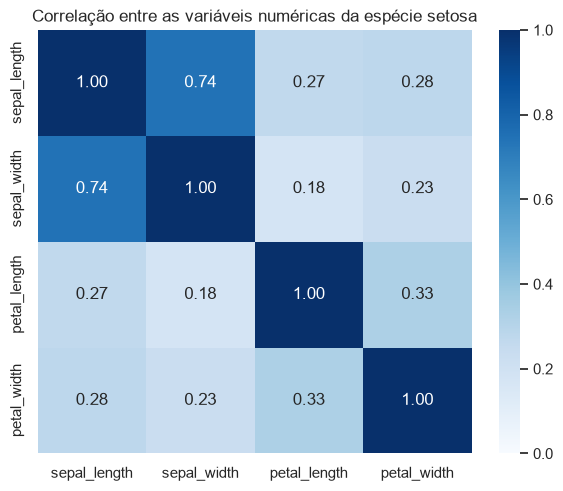

In [4]:
setosa = iris[iris['species'] == 'setosa']
correlacao_setosa = setosa.corr(numeric_only=True)

print(f'Flores da espécie setosa: {len(setosa)}\n')
print(correlacao_setosa.round(2).to_string())

pares = correlacao_setosa.where(np.triu(np.ones(correlacao_setosa.shape, dtype=bool), k=1)).stack().dropna()
print('\nPares de variáveis, do mais para o menos correlacionado:')
print(pares.sort_values(ascending=False).round(2).to_string())

plt.figure(figsize=(7, 5.5))
sns.heatmap(correlacao_setosa, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Correlação entre as variáveis numéricas da espécie setosa')
plt.show()

## Questão 2

Utilizando o dataset titanic, proponha um gráfico que apresente a distribuição das idades dos passageiros, diferenciando os dados por sexo e incluindo uma curva de densidade (KDE).

Passageiros sem idade informada: 177 de 891

        count   mean    std   min   25%   50%   75%   max
sex                                                      
female  261.0  27.92  14.11  0.75  18.0  27.0  37.0  63.0
male    453.0  30.73  14.68  0.42  21.0  29.0  39.0  80.0


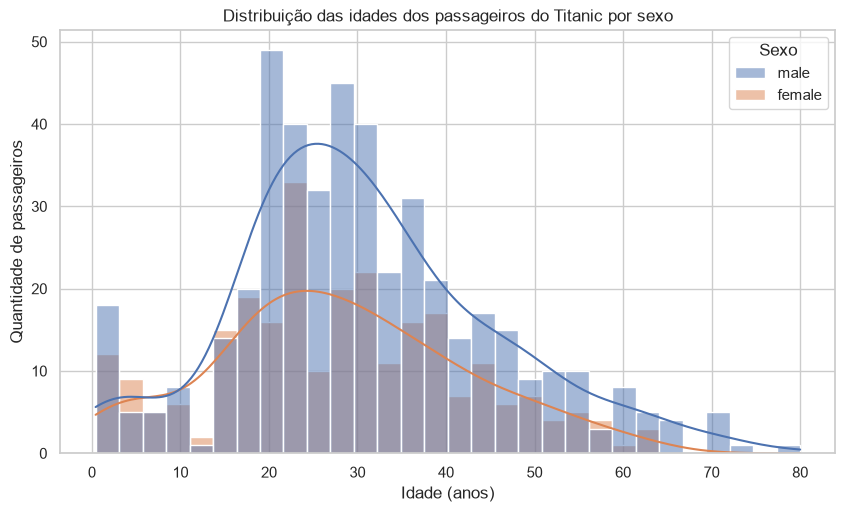

In [3]:
print(f"Passageiros sem idade informada: {titanic['age'].isna().sum()} de {len(titanic)}\n")
print(titanic.groupby('sex')['age'].describe().round(2).to_string())

plt.figure(figsize=(10, 5.5))
ax = sns.histplot(data=titanic, x='age', hue='sex', kde=True, bins=30)

ax.get_legend().set_title('Sexo')
plt.title('Distribuição das idades dos passageiros do Titanic por sexo')
plt.xlabel('Idade (anos)')
plt.ylabel('Quantidade de passageiros')
plt.show()

## Questão 3

Utilizando novamente o dataset titanic, analise a distribuição das idades dos passageiros em função da classe, segmentando os dados por sexo, de modo a construir uma visualização que permita comparar a tendência central, a dispersão e possíveis valores extremos entre os grupos.

               count   mean    std   min    25%   50%    75%   max
class  sex                                                        
First  female   85.0  34.61  13.61  2.00  23.00  35.0  44.00  63.0
       male    101.0  41.28  15.14  0.92  30.00  40.0  51.00  80.0
Second female   74.0  28.72  12.87  2.00  22.25  28.0  36.00  57.0
       male     99.0  30.74  14.79  0.67  23.00  30.0  36.75  70.0
Third  female  102.0  21.75  12.73  0.75  14.12  21.5  29.75  63.0
       male    253.0  26.51  12.16  0.42  20.00  25.0  33.00  74.0


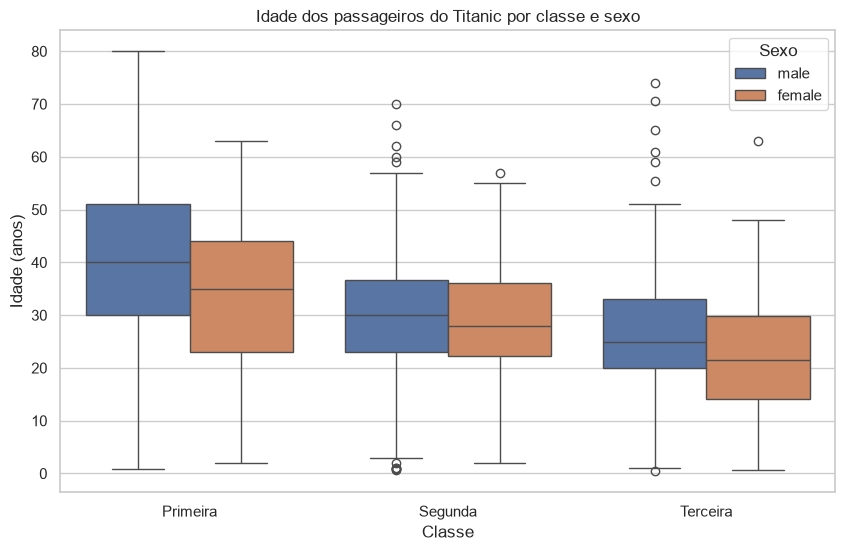

In [4]:
resumo_idades = titanic.groupby(['class', 'sex'], observed=True)['age'].describe()
print(resumo_idades.round(2).to_string())

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=titanic, x='class', y='age', hue='sex')

ax.set_xticks(range(3))
ax.set_xticklabels(['Primeira', 'Segunda', 'Terceira'])
ax.get_legend().set_title('Sexo')
plt.title('Idade dos passageiros do Titanic por classe e sexo')
plt.xlabel('Classe')
plt.ylabel('Idade (anos)')
plt.show()

## Questão 4

Utilizando o dataset mpg, analise a relação entre a potência dos veículos (horsepower) e o consumo de combustível (mpg), construindo uma visualização que permita identificar a tendência entre essas variáveis e interpretar seu comportamento.

Veículos sem a potência informada: 6 de 398
Correlação entre horsepower e mpg: -0.78


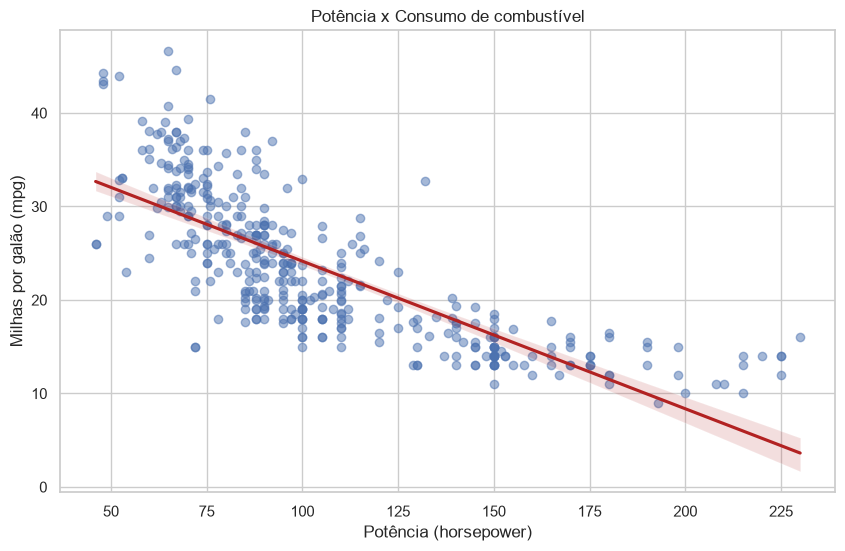

In [2]:
veiculos = mpg.dropna(subset=['horsepower', 'mpg'])
correlacao_hp_mpg = veiculos['horsepower'].corr(veiculos['mpg'])

print(f'Veículos sem a potência informada: {len(mpg) - len(veiculos)} de {len(mpg)}')
print(f'Correlação entre horsepower e mpg: {correlacao_hp_mpg:.2f}')

plt.figure(figsize=(10, 6))
sns.regplot(
    data=veiculos,
    x='horsepower',
    y='mpg',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'firebrick'},
)

plt.title('Potência x Consumo de combustível')
plt.xlabel('Potência (horsepower)')
plt.ylabel('Milhas por galão (mpg)')
plt.show()

## Questão 5

Utilizando o dataset `paises.csv`, calcule a correlação entre GDP per capita, Literacy (%), Infant mortality (per 1000 births) e Phones (per 1000), apresentando o resultado em um heatmap com os valores numéricos exibidos.

Países sem o dado (gravado como 0 no arquivo):
GDP ($ per capita)                     1
Literacy (%)                          18
Infant mortality (per 1000 births)     3
Phones (per 1000)                      4

                                    GDP ($ per capita)  Literacy (%)  Infant mortality (per 1000 births)  Phones (per 1000)
GDP ($ per capita)                                1.00          0.51                               -0.60               0.83
Literacy (%)                                      0.51          1.00                               -0.77               0.60
Infant mortality (per 1000 births)               -0.60         -0.77                                1.00              -0.67
Phones (per 1000)                                 0.83          0.60                               -0.67               1.00


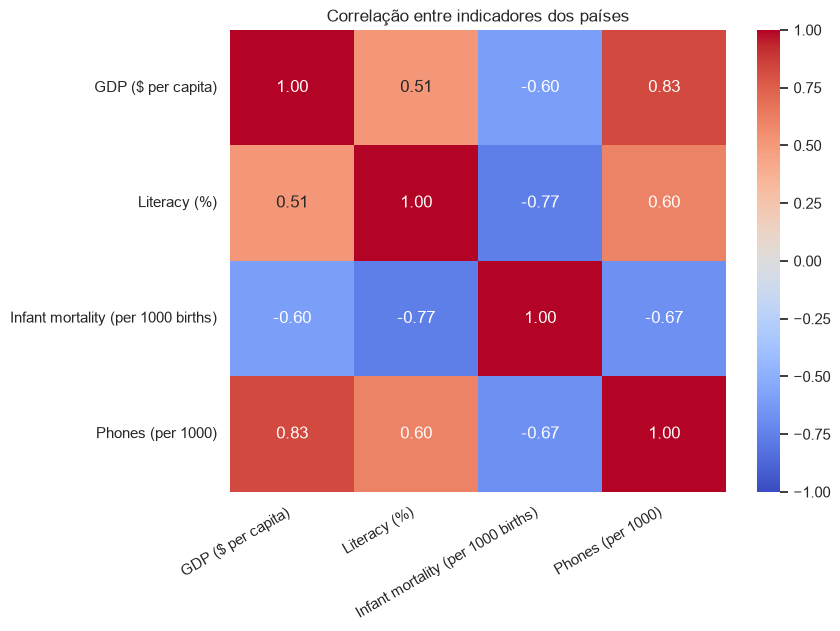

In [6]:
colunas = ['GDP ($ per capita)', 'Literacy (%)', 'Infant mortality (per 1000 births)', 'Phones (per 1000)']

indicadores = paises[colunas].replace(0, np.nan)

print('Países sem o dado (gravado como 0 no arquivo):')
print(indicadores.isna().sum().to_string())

correlacao_paises = indicadores.corr()
print()
print(correlacao_paises.round(2).to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(correlacao_paises, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlação entre indicadores dos países')
plt.xticks(rotation=30, ha='right')
plt.show()